# PathPack: оптимизация локализации правок

20 dev-задач SWE-bench Verified. Счётчик `ceil(UTF-8 bytes / 4)` по всему сериализованному контексту. Эталонный патч в отбор не входит.

v0.4 остаётся основной версией. v0.5 и v0.5.1 на этой выборке её не заменяют. Числа ниже читаются из сохранённых CSV, а не задаются в тексте ячеек.


## Архитектура, которая сравнивалась

v0.4 ранжирует чанки одной формулой: лексика, символ, граф, затем штраф похожести и стоимость. Граф — лучший путь от трёх зёрен BM25, по умолчанию два перехода, оба направления рёбер.

v0.5 сначала оставляет не больше 24 файлов, затем чанки. Этот потолок и есть потеря файлов.

v0.5.1 оставляет FileScore признаком и не отсекает файл потолком. Файл может оцениваться по целым функциям, в контекст попадают мелкие чанки. Бонус первого чанка равен нулю. Отдельного линейного члена diversity нет: diversity остаётся штрафом и бонусом поверх формулы.


In [1]:
from pathlib import Path
import csv
ROOT = Path.cwd()
if not (ROOT / 'output' / 'v05_dev' / 'summary.csv').exists():
    ROOT = ROOT.parent

def load(path):
    with open(path, newline='') as f:
        return list(csv.DictReader(f))

v05 = load(ROOT / 'output/v05_dev/summary.csv')
v51 = load(ROOT / 'output/v051_dev/summary.csv')
probe = load(ROOT / 'output/v04_graph_probe/summary.csv')
profile = load(ROOT / 'output/v051_dev/stage_profile_mean.csv')

def row(rows, method, budget='2048'):
    hit = [r for r in rows if r['method']==method and str(r['budget'])==str(budget)]
    if not hit:
        raise KeyError((method, budget))
    return hit[0]

def show(title, rows, methods):
    print(title)
    header = f"{'method':<28} {'file':>8} {'fn':>8} {'complete':>8} {'line':>8} {'n_line':>6} {'latency':>8}"
    print(header)
    for method in methods:
        r = row(rows, method)
        print(f"{method:<28} {float(r['file_recall']):8.4f} {float(r['function_recall']):8.4f} "
              f"{float(r['complete_function_recall']):8.4f} {float(r['changed_line_recall']):8.4f} "
              f"{r['changed_line_recall_evaluable']:>6} {float(r['latency_sec']):8.3f}")

show('2048 tokens, output/v05_dev', v05, ['bm25','graph-expand','pathpack-v4','pathpack-v5'])
print()
show('2048 tokens, output/v051_dev', v51, ['pathpack-v4','pathpack-v51','pathpack-v51/coarse-coarse','pathpack-v51/fine-fine','pathpack-v51/global-fine'])
print()
show('2048 tokens, graph probe', probe, ['v4-hops-1','v4-hops-2','v4-hops-3','v4-callers','v4-callees'])


2048 tokens, output/v05_dev
method                           file       fn complete     line n_line  latency
bm25                           0.3500   0.1111   0.1111   0.1429     14    0.053
graph-expand                   0.3250   0.1111   0.1111   0.1429     14    0.153
pathpack-v4                    0.7250   0.2024   0.0913   0.1480     14    0.607
pathpack-v5                    0.5750   0.1151   0.0595   0.1480     14    0.496

2048 tokens, output/v051_dev
method                           file       fn complete     line n_line  latency
pathpack-v4                    0.7250   0.2024   0.0913   0.1480     14    0.568
pathpack-v51                   0.6250   0.1984   0.0873   0.1718     14    0.901
pathpack-v51/coarse-coarse     0.3250   0.0833   0.0833   0.0714     14    0.600
pathpack-v51/fine-fine         0.6250   0.1429   0.0873   0.1480     14    0.780
pathpack-v51/global-fine       0.7750   0.1429   0.0873   0.1718     14    0.816

2048 tokens, graph probe
method                   

## Метрики по бюджетам

File Recall v0.4 растёт с бюджетом. Changed Line Recall v0.4 на этой кривой плоский: то же значение при 1024, 2048 и 4096. v0.5 совпадает сам с собой при 1024 и 2048.


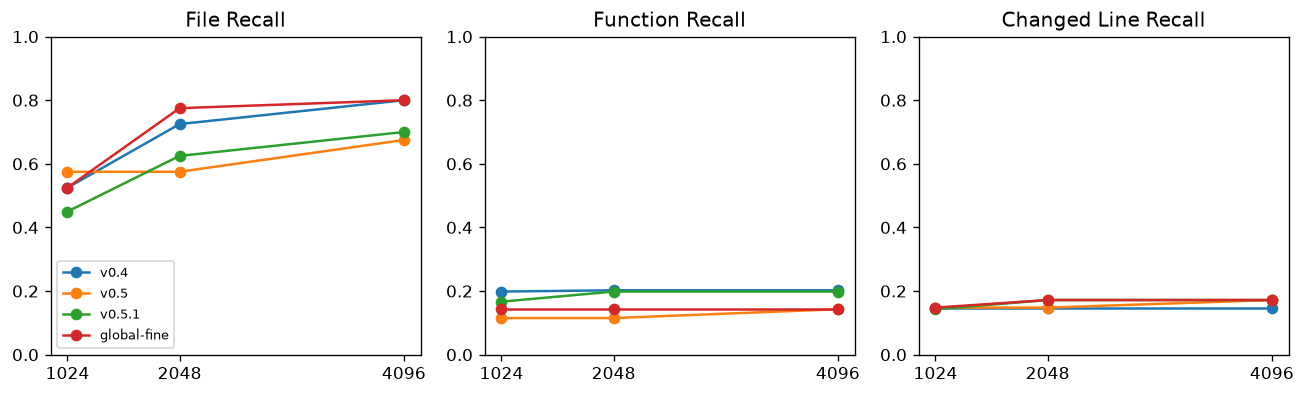

In [1]:
import matplotlib.pyplot as plt
metrics = [('file_recall','File Recall'), ('function_recall','Function Recall'), ('changed_line_recall','Changed Line Recall')]
series = {
    'v0.4': [r for r in v05 if r['method']=='pathpack-v4'],
    'v0.5': [r for r in v05 if r['method']=='pathpack-v5'],
    'v0.5.1': [r for r in v51 if r['method']=='pathpack-v51'],
    'global-fine': [r for r in v51 if r['method']=='pathpack-v51/global-fine'],
}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True)
for ax, (key, title) in zip(axes, metrics):
    for name, rows in series.items():
        rows = sorted(rows, key=lambda r: int(r['budget']))
        ax.plot([int(r['budget']) for r in rows], [float(r[key]) for r in rows], marker='o', label=name)
    ax.set_title(title)
    ax.set_xticks([1024, 2048, 4096])
    ax.set_ylim(0, 1)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


## Глубина графа v0.4

Тот же ранжировщик, другой `hops` или направление ребра. File Recall глубины 3 совпадает с глубиной 2 на всех 20 задачах. Средний прирост строк создаёт одна задача, `psf__requests-1766`. Парный 95% интервал этой разности включает 0.


candidate      metric                       diff                     ci      +/=/-
v4-hops-3      file_recall                0.0000 [ 0.0000,  0.0000]   0/20/0 
v4-hops-3      function_recall            0.0595 [ 0.0000,  0.1706]   2/16/0 
v4-hops-3      changed_line_recall        0.0714 [ 0.0000,  0.2143]   1/13/0 
v4-callers     file_recall               -0.1250 [-0.2750,  0.0000]   0/17/3 
v4-callers     function_recall           -0.0873 [-0.2262,  0.0000]   0/15/3 
v4-callers     changed_line_recall        0.0000 [ 0.0000,  0.0000]   0/14/0 
v4-callees     file_recall                0.0250 [ 0.0000,  0.0750]   1/19/0 
v4-callees     function_recall           -0.0556 [-0.1667,  0.0000]   0/17/1 
v4-callees     changed_line_recall        0.0238 [ 0.0000,  0.0714]   1/13/0 


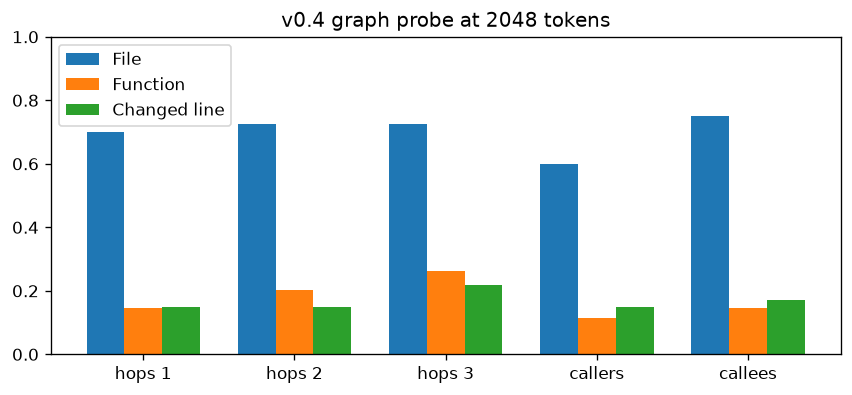

In [1]:
import json
labels = ['hops 1','hops 2','hops 3','callers','callees']
methods = ['v4-hops-1','v4-hops-2','v4-hops-3','v4-callers','v4-callees']
fig, ax = plt.subplots(figsize=(7.2, 3.4))
x = range(len(methods))
width = 0.25
for offset, key, name in ((-width,'file_recall','File'), (0,'function_recall','Function'), (width,'changed_line_recall','Changed line')):
    vals = [float(row(probe, m)[key]) for m in methods]
    ax.bar([i+offset for i in x], vals, width=width, label=name)
ax.set_xticks(list(x), labels)
ax.set_ylim(0, 1)
ax.legend()
ax.set_title('v0.4 graph probe at 2048 tokens')
fig.tight_layout()
plt.show()
comp = json.loads((ROOT/'output/v04_graph_probe/comparisons.json').read_text())
print(f"{'candidate':<14} {'metric':<24} {'diff':>8} {'ci':>22} {'+/=/-':>10}")
for item in comp:
    if item['candidate'] not in {'v4-hops-3','v4-callers','v4-callees'}:
        continue
    if item['metric'] not in {'file_recall','changed_line_recall','function_recall'}:
        continue
    lo, hi = item['ci95']
    print(f"{item['candidate']:<14} {item['metric']:<24} {item['difference']:8.4f} [{lo:7.4f}, {hi:7.4f}] "
          f"{item['wins']:>3}/{item['ties']:>2}/{item['losses']:<2}")


## Куда девается бюджет внутри найденного файла

На аудите v0.4 зелёный — покрытая эталонная строка, красный — пропущенная, жёлтый — выбранный код без пересечения с эталоном. `requests-1766` — как раз задача, которую глубина 3 закрывает целиком при бюджете 2048. Картинка ниже снята с обычного v0.4 (`hops: 2`): файл найден, изменённые строки в выбранные срезы не попали.


Changed line recall of v0.4 is 0 on this task at 1024, 2048 and 4096.
hops 3 of the same ranker moves it from 0 to 1. That is the only line-recall change in the probe.


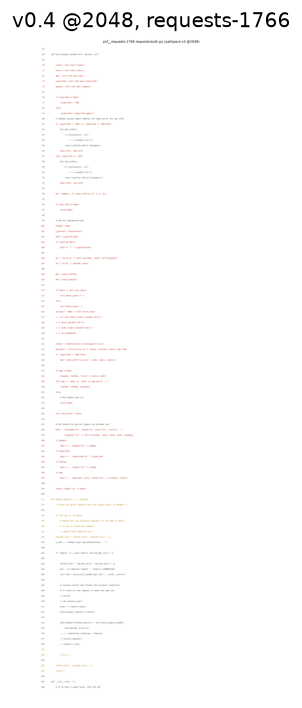

In [1]:
import matplotlib.image as mpimg
path = ROOT / 'output/v05_audit/figures/psf__requests-1766_lines.png'
img = mpimg.imread(path)
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img)
ax.axis('off')
ax.set_title('v0.4 @2048, requests-1766')
fig.tight_layout()
plt.show()
print('Changed line recall of v0.4 is 0 on this task at 1024, 2048 and 4096.')
print('hops 3 of the same ranker moves it from 0 to 1. That is the only line-recall change in the probe.')


## Профиль запроса v0.5.1

Индексация сюда не входит. Самый длинный этап запроса — diversity. Упаковка префикса пренебрежимо мала. Ускорение diversity не меняет вывод о качестве: v0.5.1 проигрывает v0.4 по файлам.


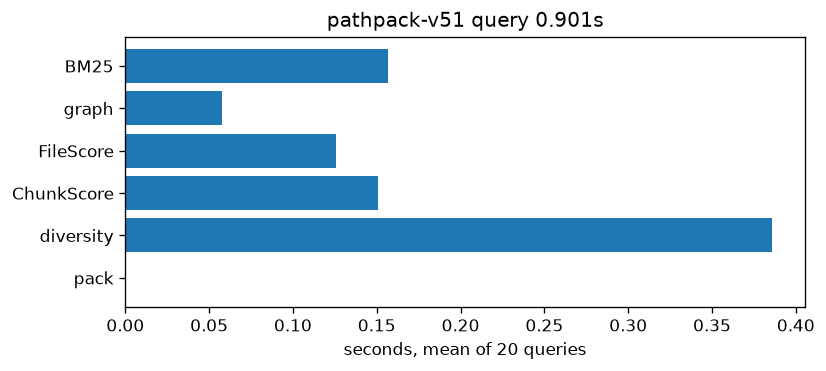

In [1]:
r = [p for p in profile if p['method']=='pathpack-v51'][0]
stages = ['candidate_sec','graph_sec','file_rank_sec','chunk_score_sec','diversity_sec','prefix_sec']
names = ['BM25','graph','FileScore','ChunkScore','diversity','pack']
vals = [float(r[s]) for s in stages]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(names[::-1], vals[::-1])
ax.set_xlabel('seconds, mean of 20 queries')
ax.set_title(f"pathpack-v51 query {float(r['query_sec']):.3f}s")
fig.tight_layout()
plt.show()


## Вывод

Soft hierarchy не сохранила File Recall v0.4: 0.625 против 0.725. Прирост Changed Line Recall равен одной задаче, и парный интервал включает 0. Целые функции как текст контекста хуже чанков. Глубина графа 3 поднимает среднее по строкам тоже за счёт одной задачи, `requests-1766`, при неизменном File Recall; интервал [0.00, 0.214] включает 0. Holdout не оценивался. Embedding не запускался.
